# 08 — Acquisition time, region confounding and curve clustering

Two of the main limits of notebooks 03–07 are that (i) the cell identifier is not available, so curves from the same cell are treated as independent (**pseudo-replication**), and (ii) cell line and measurement session coincide. The JPK files carry a **timestamp** for every curve, which gives access to both problems.

**What this notebook does**

1. extracts the acquisition time of every curve (tracked table in `results/`, so the notebook runs without the raw data);
2. reconstructs the **order of measurement**: were cytoplasm and nucleus measured interleaved or in separate blocks?
3. defines **spatial bursts** (consecutive curves taken a few seconds apart at the same spot) as a proxy for the independent unit, and quantifies the dependence between curves of the same burst: intra-class correlation, design effect and effective sample size;
4. repeats the nucleus–cytoplasm comparison at the **burst level** (Welch on burst means, cluster bootstrap, cluster permutation test, cluster-robust regression);
5. tests whether a **temporal drift** of $\log A$ within a session could explain the region difference when the two regions are measured in different time blocks.

**What it does NOT do**

- it does not recover the true cell identifier: a burst is a *lower bound* on the dependence, because several bursts may fall on the same cell;
- it does not remove or reweight any curve in notebooks 02–07;
- it cannot separate cell line from session (one session per line).

Region labels follow the data folders: `cito` = cytoplasm, `nucleo` = nucleus.

In [1]:
import warnings, json; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
import afm_tools as T

T.set_plot_style()
SEED = 20261016; RNG = np.random.default_rng(SEED); summary = {}; lines = ["MCF7R", "T47DR"]
TIMES_PATH = T.RESULTS_DIR / "acquisition_times.csv"
META = T.OUTPUT_DIR / "metadata" / "metadata_segments.csv"
if META.exists():
    m = pd.read_csv(META); m = m[m.segment_id == 0].copy()
    m["t"] = pd.to_datetime(m.time_stamp.str.replace("\\", "", regex=False).str[:23])
    m[["file_name", "group", "t"]].to_csv(TIMES_PATH, index=False); print("rebuilt", TIMES_PATH.name)
times = pd.read_csv(TIMES_PATH, parse_dates=["t"])
fit = T.load_fit_table(); fit = fit[fit.fit_status == "ok"]
df = fit.merge(times, on=["file_name", "group"]).sort_values(["cell_line", "t"]).reset_index(drop=True)
df["t_min"] = df.groupby("cell_line").t.transform(lambda s: (s - s.min()).dt.total_seconds() / 60)    # minutes from the start of the session
print(len(df), "curves with timestamp")

rebuilt acquisition_times.csv
257 curves with timestamp


## 1. Order of measurement

If cytoplasm and nucleus were measured in separate time blocks, region is confounded with time: any drift (cantilever wear, cell stress, temperature, a slow change of the setpoint) would add to the region difference.

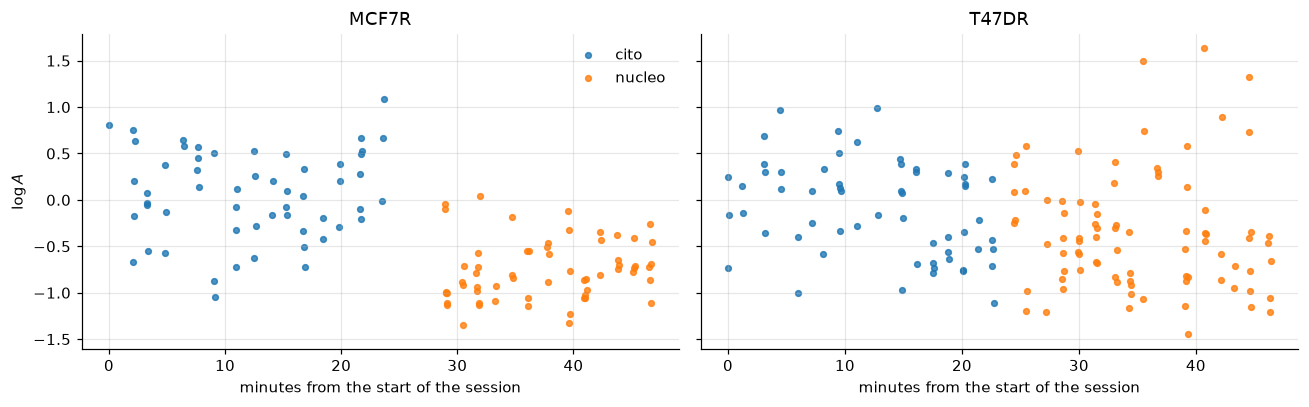

overlap in time between the two regions [min]: {'MCF7R': 0.0, 'T47DR': 0.0}


n  start_min  end_min  median_min
line  region                                    
MCF7R cito    55        0.0     23.6        12.5
      nucleo  60       28.9     46.8        37.8
T47DR cito    59        0.0     22.7        14.8
      nucleo  83       24.4     46.4        34.3

In [2]:
rows = []
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for a, l in zip(ax, lines):
    d = df[df.cell_line == l]
    for r_, c in [("cito", "C0"), ("nucleo", "C1")]:
        s = d[d.region == r_]; a.scatter(s.t_min, s.logA, s=14, c=c, label=r_, alpha=.8)
        rows.append(dict(line=l, region=r_, n=len(s), start_min=s.t_min.min(), end_min=s.t_min.max(), median_min=s.t_min.median()))
    a.set_title(l); a.set_xlabel("minutes from the start of the session")
ax[0].set_ylabel(r"$\log A$"); ax[0].legend(); plt.tight_layout(); plt.show()
blocks = pd.DataFrame(rows).set_index(["line", "region"]); summary["measurement_blocks"] = {f"{k[0]}|{k[1]}": v for k, v in blocks.round(2).to_dict("index").items()}
overlap = {l: float(max(0, min(blocks.loc[(l, "cito"), "end_min"], blocks.loc[(l, "nucleo"), "end_min"]) - max(blocks.loc[(l, "cito"), "start_min"], blocks.loc[(l, "nucleo"), "start_min"]))) for l in lines}
summary["time_overlap_min"] = overlap; print("overlap in time between the two regions [min]:", overlap); blocks.round(1)

## 2. Spatial bursts

The gaps between consecutive curves are bimodal: about 2 s (the next curve at the same spot) against 60–100 s (the tip moves to a new location). A gap above a threshold starts a new **burst**; the result is stable for any threshold between ~5 and ~60 s.

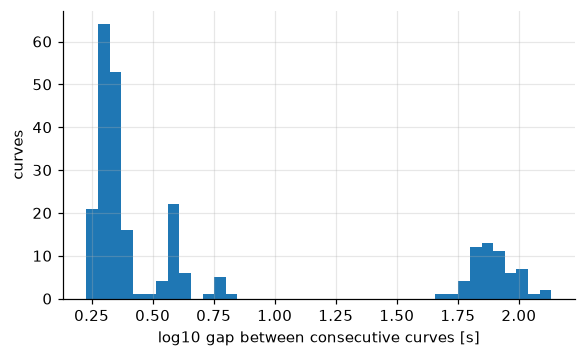

,MCF7R cito,MCF7R nucleo,T47DR cito,T47DR nucleo
threshold_s,,,,
3,24,26,27,25
5,17,14,20,18
10,16,13,17,16
30,16,13,17,16
60,16,13,16,15


curves  bursts  curves_per_burst
cell_line region                                  
MCF7R     cito        55      16              3.44
          nucleo      60      13              4.62
T47DR     cito        59      17              3.47
          nucleo      83      16              5.19

In [3]:
df["gap_s"] = df.groupby(["cell_line", "region"]).t.diff().dt.total_seconds()
fig, ax = plt.subplots(figsize=(6, 3.4)); ax.hist(np.log10(df.gap_s.dropna()), bins=40); ax.set_xlabel("log10 gap between consecutive curves [s]"); ax.set_ylabel("curves"); plt.show()
def burst_ids(d, thr):
    new = (d.gap_s.isna()) | (d.gap_s > thr); return new.cumsum()
rows = []
for thr in [3, 5, 10, 30, 60]:
    n = df.groupby(["cell_line", "region"], group_keys=False).apply(lambda d: burst_ids(d, thr).nunique())
    rows.append(dict(threshold_s=thr, **{f"{k[0]} {k[1]}": v for k, v in n.items()}))
thr_tab = pd.DataFrame(rows).set_index("threshold_s"); summary["bursts_vs_threshold"] = thr_tab.to_dict("index"); display(thr_tab)
THR = 10
df["burst"] = df.groupby(["cell_line", "region"], group_keys=False).apply(lambda d: burst_ids(d, THR))
df["cluster"] = df.cell_line + "_" + df.region + "_" + df.burst.astype(str)
sizes = df.groupby(["cell_line", "region"]).cluster.agg(["count", "nunique"]).rename(columns={"count": "curves", "nunique": "bursts"}); sizes["curves_per_burst"] = sizes.curves / sizes.bursts
summary["bursts"] = {f"{k[0]}|{k[1]}": v for k, v in sizes.round(2).to_dict("index").items()}; sizes.round(2)

## 3. How dependent are curves of the same burst?

One-way ANOVA intra-class correlation (ICC) of $\log A$ within each group, the **design effect** $\mathrm{deff}=1+(\bar m-1)\,\mathrm{ICC}$ (with $\bar m$ the mean burst size) and the **effective sample size** $n_{eff}=n/\mathrm{deff}$: the number of independent curves that would give the same precision. The ICC is also computed with a bootstrap over bursts.

In [4]:
def icc(d, col="logA", cl="cluster"):
    g = d.groupby(cl)[col]; k = g.ngroups; n = len(d); ni = g.size().to_numpy(); mu = d[col].mean()
    ssb = (ni * (g.mean().to_numpy() - mu) ** 2).sum(); ssw = ((d[col] - g.transform("mean")) ** 2).sum()
    msb, msw = ssb / (k - 1), ssw / (n - k); m0 = (n - (ni ** 2).sum() / n) / (k - 1)
    return (msb - msw) / (msb + (m0 - 1) * msw), n / k
rows = []
for (l, r_), d in df.groupby(["cell_line", "region"]):
    i, mbar = icc(d); cl = d.cluster.unique(); bs = []
    for _ in range(1000):
        pick = RNG.choice(cl, len(cl)); dd = pd.concat([d[d.cluster == c].assign(cluster=f"{c}_{j}") for j, c in enumerate(pick)]); bs.append(icc(dd)[0])
    deff = 1 + (mbar - 1) * i
    rows.append(dict(line=l, region=r_, n=len(d), bursts=len(cl), mean_burst_size=mbar, ICC=i, ICC_lo=np.quantile(bs, .16), ICC_hi=np.quantile(bs, .84), design_effect=deff, n_effective=len(d) / deff))
icc_tab = pd.DataFrame(rows).set_index(["line", "region"]); summary["icc"] = {f"{k[0]}|{k[1]}": v for k, v in icc_tab.round(3).to_dict("index").items()}; icc_tab.round(3)

n  bursts  mean_burst_size    ICC  ICC_lo  ICC_hi  \
line  region                                                       
MCF7R cito    55      16            3.438  0.177   0.065   0.253   
      nucleo  60      13            4.615 -0.048  -0.134   0.041   
T47DR cito    59      17            3.471  0.182   0.037   0.284   
      nucleo  83      16            5.188  0.100   0.008   0.180   

              design_effect  n_effective  
line  region                              
MCF7R cito            1.430       38.450  
      nucleo          0.825       72.738  
T47DR cito            1.451       40.666  
      nucleo          1.419       58.481

## 4. Nucleus–cytoplasm comparison at the burst level

Four ways to treat the dependence, compared with the naive curve-level test of notebook 03:

- **Welch on burst means** (the burst as unit);
- **cluster bootstrap** (resample bursts within each region, mean of the curves);
- **cluster permutation test** (permute the region label across whole bursts);
- **cluster-robust OLS** of $\log A$ on region, with sandwich standard errors clustered by burst.

In [5]:
def cluster_stats(d):
    cm = d.groupby(["cluster", "region"]).logA.mean().reset_index(); a = cm[cm.region == "nucleo"].logA.to_numpy(); b = cm[cm.region == "cito"].logA.to_numpy()
    return a, b
def cluster_boot(d, nb=4000):
    cl_n = d[d.region == "nucleo"].cluster.unique(); cl_c = d[d.region == "cito"].cluster.unique(); gm = d.groupby("cluster").logA.agg(["sum", "count"])
    out = np.empty(nb)
    for i in range(nb):
        pn, pc = RNG.choice(cl_n, len(cl_n)), RNG.choice(cl_c, len(cl_c))
        out[i] = gm.loc[pn, "sum"].sum() / gm.loc[pn, "count"].sum() - gm.loc[pc, "sum"].sum() / gm.loc[pc, "count"].sum()
    return out
def cluster_perm(d, n=5000):
    cm = d.groupby("cluster").agg(region=("region", "first"), s=("logA", "sum"), c=("logA", "count")).reset_index(); obs = None; out = np.empty(n)
    def stat(lab): 
        a = cm[lab == "nucleo"]; b = cm[lab == "cito"]; return a.s.sum() / a.c.sum() - b.s.sum() / b.c.sum()
    obs = stat(cm.region.to_numpy())
    for i in range(n): out[i] = stat(RNG.permutation(cm.region.to_numpy()))
    return obs, (np.sum(np.abs(out) >= abs(obs)) + 1) / (n + 1)
def cluster_ols(d):
    X = np.c_[np.ones(len(d)), (d.region == "nucleo").astype(float)]; y = d.logA.to_numpy(); beta = np.linalg.lstsq(X, y, rcond=None)[0]; res = y - X @ beta
    XtXi = np.linalg.inv(X.T @ X); meat = sum(np.outer(X[idx].T @ res[idx], X[idx].T @ res[idx]) for idx in d.groupby("cluster").indices.values()); G = d.cluster.nunique()
    V = XtXi @ meat @ XtXi * G / (G - 1); return beta[1], np.sqrt(V[1, 1]), G
rows = []
for l in lines:
    d = df[df.cell_line == l]; xn, xc = d[d.region == "nucleo"].logA.to_numpy(), d[d.region == "cito"].logA.to_numpy()
    a, b = cluster_stats(d); bs = cluster_boot(d); obs, pperm = cluster_perm(d); beta, se, G = cluster_ols(d)
    rows.append(dict(line=l, delta=xn.mean() - xc.mean(), p_naive_welch=stats.ttest_ind(xn, xc, equal_var=False).pvalue, delta_burst_means=a.mean() - b.mean(), p_welch_bursts=stats.ttest_ind(a, b, equal_var=False).pvalue,
                     boot_lo95=np.quantile(bs, .025), boot_hi95=np.quantile(bs, .975), p_cluster_perm=pperm, ols_delta=beta, ols_se=se, p_cluster_ols=2 * stats.t.sf(abs(beta / se), df=G - 2), n_bursts=G,
                     naive_se=np.hypot(xn.std(ddof=1) / np.sqrt(len(xn)), xc.std(ddof=1) / np.sqrt(len(xc)))))
cl = pd.DataFrame(rows).set_index("line"); cl["se_inflation"] = cl.ols_se / cl.naive_se; summary["burst_level_comparison"] = cl.round(5).to_dict("index"); cl.round(4)

,delta,p_naive_welch,delta_burst_means,p_welch_bursts,boot_lo95,boot_hi95,p_cluster_perm,ols_delta,ols_se,p_cluster_ols,n_bursts,naive_se,se_inflation
line,,,,,,,,,,,,,
MCF7R,-0.8139,0.0000,-0.8432,0.0000,-0.9693,-0.6603,0.0002,-0.8139,0.0811,0.0000,29,0.0770,1.0534
T47DR,-0.2468,0.0114,-0.2173,0.0952,-0.4646,-0.0301,0.0492,-0.2468,0.1118,0.0349,33,0.0963,1.1615


## 5. Could a temporal drift explain the region difference?

Because the regions were measured in separate blocks, a monotonic drift of $\log A$ with time would shift the nucleus (measured later) with respect to the cytoplasm. We estimate the drift **within** each block (where region is constant), project it across the gap between the block centres, and compare it with the observed $\Delta$. A cluster-robust regression of $\log A$ on region **and** time is also reported (the coefficient of region is then the jump between blocks beyond the within-block trend).

In [6]:
rows = []
for l in lines:
    d = df[df.cell_line == l]; slopes = {}
    for r_ in ["cito", "nucleo"]:
        s = d[d.region == r_]; sl, ic, rho, p, se = stats.linregress(s.t_min, s.logA); slopes[r_] = (sl, se, stats.spearmanr(s.t_min, s.logA)[0])
    # regression logA ~ 1 + nucleus + t (common within-block slope): the coefficient of 'nucleus' is the difference between the blocks at the SAME time
    X = np.c_[np.ones(len(d)), (d.region == "nucleo").astype(float), d.t_min.to_numpy()]; y = d.logA.to_numpy()
    beta = np.linalg.lstsq(X, y, rcond=None)[0]; res = y - X @ beta; XtXi = np.linalg.inv(X.T @ X)
    meat = sum(np.outer(X[i].T @ res[i], X[i].T @ res[i]) for i in d.groupby("cluster").indices.values()); G = d.cluster.nunique(); V = XtXi @ meat @ XtXi * G / (G - 1)
    slope, se_slope = beta[2], np.sqrt(V[2, 2]); gap_min = d[d.region == "nucleo"].t_min.mean() - d[d.region == "cito"].t_min.mean()
    delta_obs = d[d.region == "nucleo"].logA.mean() - d[d.region == "cito"].logA.mean()
    rows.append(dict(line=l, slope_cito_per_10min=10 * slopes["cito"][0], slope_nucleo_per_10min=10 * slopes["nucleo"][0], spearman_cito=slopes["cito"][2], spearman_nucleo=slopes["nucleo"][2],
                     common_slope_per_10min=10 * slope, common_slope_se=10 * se_slope, block_gap_min=gap_min, drift_over_gap=slope * gap_min, delta_observed=delta_obs,
                     delta_at_common_time=beta[1], delta_at_common_time_se=np.sqrt(V[1, 1]), p_delta_at_common_time=2 * stats.t.sf(abs(beta[1] / np.sqrt(V[1, 1])), df=G - 3)))
dr = pd.DataFrame(rows).set_index("line"); summary["drift"] = dr.round(4).to_dict("index"); dr.round(3)

,slope_cito_per_10min,slope_nucleo_per_10min,spearman_cito,spearman_nucleo,common_slope_per_10min,common_slope_se,block_gap_min,drift_over_gap,delta_observed,delta_at_common_time,delta_at_common_time_se,p_delta_at_common_time
line,,,,,,,,,,,,
MCF7R,0.045,0.086,0.025,0.231,0.063,0.060,25.299,0.160,-0.814,-0.974,0.170,0.000
T47DR,-0.225,-0.058,-0.322,-0.149,-0.133,0.071,22.188,-0.295,-0.247,0.049,0.175,0.783


The same cluster-robust regression (region + common time trend) for two other observables of notebooks 06–07: the **free exponent** and the **force at a fixed indentation of 300 nm**. If the trend explains $\log A$ in T47DR, it should explain them too.

In [7]:
PROF = T.RESULTS_DIR / "force_indentation_profiles.csv"
d_all = df.merge(pd.read_csv(PROF)[["file_name", "group", "F_300nm"]], on=["file_name", "group"], how="left"); d_all["logF300"] = np.log(d_all.F_300nm.clip(lower=1e-3))
def adjust(d, col):
    d = d.dropna(subset=[col]); X = np.c_[np.ones(len(d)), (d.region == "nucleo").astype(float), d.t_min.to_numpy()]; y = d[col].to_numpy()
    beta = np.linalg.lstsq(X, y, rcond=None)[0]; res = y - X @ beta; XtXi = np.linalg.inv(X.T @ X)
    meat = sum(np.outer(X[i].T @ res[i], X[i].T @ res[i]) for i in d.groupby("cluster").indices.values()); G = d.cluster.nunique(); V = XtXi @ meat @ XtXi * G / (G - 1)
    obs = d[d.region == "nucleo"][col].mean() - d[d.region == "cito"][col].mean()
    return dict(observed=obs, slope_per_10min=10 * beta[2], slope_p=2 * stats.t.sf(abs(beta[2] / np.sqrt(V[2, 2])), df=G - 3), at_common_time=beta[1], se=np.sqrt(V[1, 1]), p=2 * stats.t.sf(abs(beta[1] / np.sqrt(V[1, 1])), df=G - 3))
rows = [dict(line=l, observable=lab_, **adjust(d_all[d_all.cell_line == l], col)) for l in lines for col, lab_ in [("logA", "log A"), ("logF300", "log F(300 nm)"), ("exponent_hat", "free exponent")]]
adj = pd.DataFrame(rows).set_index(["line", "observable"]); summary["adjusted_for_time"] = {f"{k[0]}|{k[1]}": v for k, v in adj.round(5).to_dict("index").items()}; adj.round(4)

observed  slope_per_10min  slope_p  at_common_time  \
line  observable                                                          
MCF7R log A           -0.8139           0.0632   0.3027         -0.9737   
      log F(300 nm)   -0.7639           0.0851   0.1499         -0.9792   
      free exponent    0.0076          -0.0214   0.0142          0.0617   
T47DR log A           -0.2468          -0.1331   0.0710          0.0486   
      log F(300 nm)   -0.3506          -0.1627   0.0142          0.0072   
      free exponent    0.0699           0.0047   0.5227          0.0594   

                         se       p  
line  observable                     
MCF7R log A          0.1697  0.0000  
      log F(300 nm)  0.1535  0.0000  
      free exponent  0.0217  0.0085  
T47DR log A          0.1745  0.7826  
      log F(300 nm)  0.1643  0.9655  
      free exponent  0.0172  0.0017

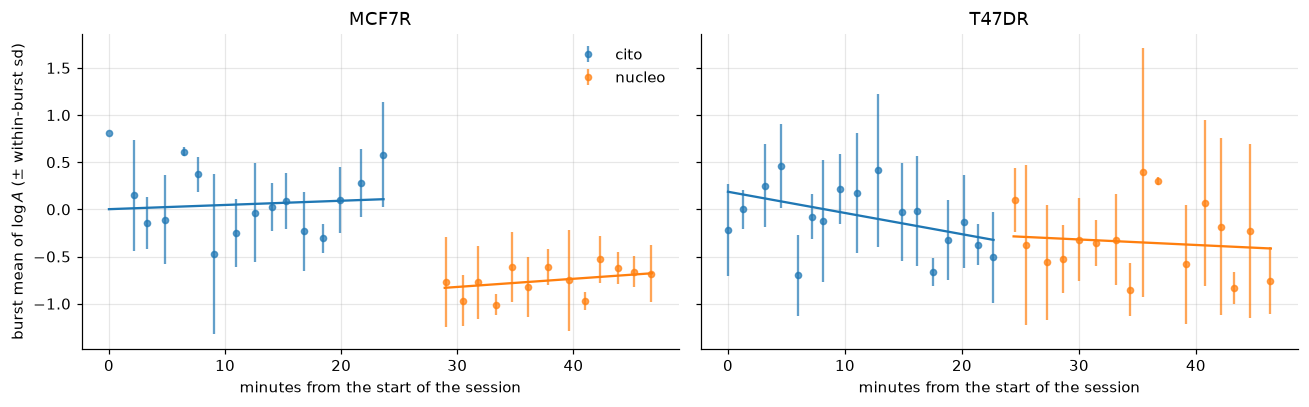

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for a, l in zip(ax, lines):
    d = df[df.cell_line == l]
    for r_, c in [("cito", "C0"), ("nucleo", "C1")]:
        s = d[d.region == r_]; cm = s.groupby("cluster").agg(t=("t_min", "mean"), y=("logA", "mean"), sd=("logA", "std"), n=("logA", "size")); a.errorbar(cm.t, cm.y, cm.sd.fillna(0), fmt="o", c=c, alpha=.7, ms=4, label=r_)
        b = np.polyfit(s.t_min, s.logA, 1); tt = np.array([s.t_min.min(), s.t_min.max()]); a.plot(tt, np.polyval(b, tt), c=c)
    a.set_title(l); a.set_xlabel("minutes from the start of the session")
ax[0].set_ylabel(r"burst mean of $\log A$ (± within-burst sd)"); ax[0].legend(); plt.tight_layout(); plt.show()
json.dump(summary, open(T.RESULTS_DIR / "08_summary.json", "w"), indent=1, default=float)

## Interpretation and limits

- **Measurement order.** In both sessions the cytoplasm was measured first (≈ 0–23 min) and the nucleus afterwards (≈ 25–47 min), with **no overlap in time**: region is confounded with time. Any drift of $\log A$ during the session adds to the region difference, and the two cannot be separated by design.
- **Bursts and dependence.** The curves come in bursts of ≈ 3–5 consecutive curves (2 s apart) at the same spot, with 13–17 bursts per group, stable for any gap threshold between 5 and 60 s. The within-burst correlation is modest: ICC ≈ 0.10–0.18 in three groups and ≈ 0 in MCF7R nucleus, design effect ≈ 1.4 and effective sample sizes of 38–73 curves instead of 55–83. Pseudo-replication at this level is therefore **real but mild**: the standard error of $\Delta$ grows by 5% (MCF7R) and 16% (T47DR). Several bursts may belong to the same cell, so these are lower bounds.
- **Burst-level comparison.** MCF7R is unchanged ($p<10^{-3}$ with every method). For T47DR the evidence weakens: the naive Welch test gives $p=0.011$, while the burst-level tests give $p=0.035$ (cluster-robust regression), $0.049$ (cluster permutation) and $0.095$ (Welch on burst means), and the cluster-bootstrap interval for $\Delta$ is $[-0.46,-0.03]$. T47DR is borderline at the burst level.
- **Temporal drift.** In T47DR $\log A$ decreases during the session (common within-block slope $\approx-0.13$ per 10 min, ≈ 1.9 standard errors). Projected over the ≈ 22 min between the block centres, this drift alone predicts $\Delta\approx-0.30$, i.e. the whole observed difference ($-0.25$): after removing the trend, $\Delta=+0.05\pm0.17$, compatible both with zero and with the observed value. **The T47DR nucleus–cytoplasm difference cannot be distinguished from a temporal drift** (of instrumental or biological origin). In MCF7R the within-block slope is positive ($+0.06\pm0.06$ per 10 min), i.e. opposite to the effect: after removing it the difference is larger, $-0.97\pm0.17$.
- **Other observables.** The force at 300 nm behaves like $\log A$: in T47DR it drifts down during the session ($-0.16$ per 10 min, $p=0.014$) and the nucleus–cytoplasm difference at a common time is $0.01\pm0.16$; in MCF7R it stays $-0.98\pm0.15$. The **free exponent** is different: in T47DR it shows no drift (slope $0.005$ per 10 min, $p=0.52$) and the nuclear excess survives the correction ($+0.059\pm0.017$, $p=0.002$); in MCF7R, after removing a small negative trend, it also becomes significant ($+0.062\pm0.022$). So the one T47DR regional difference robust to the time confounding is in the **form** of the response (exponent), not in the stiffness amplitude.
- **What would settle it.** Repeating the measurement with the two regions **interleaved** (alternating cytoplasm and nucleus on the same cells) and recording the cell identifier; with the present data the conclusion "nucleus softer than cytoplasm" is solid for MCF7R and only suggestive for T47DR.

## Output produced

```text
results/acquisition_times.csv   acquisition timestamp of every curve (tracked)
results/08_summary.json         measurement blocks, bursts, ICC and design effect, burst-level tests, drift and adjusted differences
```